In [1]:
#PRACT1 BHAGYASHREE BANSODE
!pip install openpyxl


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
# 1. Load data from different file formats
csv_data = pd.read_csv("Sales_Data.csv")
excel_data = pd.read_excel("Sales_Data.xlsx")
json_data = pd.read_json("Sales_Data.json")

In [2]:
# 2. Display sample records
print("CSV Data:")
print(csv_data.head())
print("\nExcel Data:")
print(excel_data.head())
print("\nJSON Data:")
print(json_data.head())

CSV Data:
   Order_ID       Product     Category  Quantity   Sales Region
0      1001        Laptop  Electronics         2  120000   West
1      1002  Mobile Phone  Electronics         5   75000   West
2      1003  Office Chair    Furniture         4   32000  South
3      1004          Desk    Furniture         3   27000  North
4      1005       Printer  Electronics         2   30000   East

Excel Data:
   Order_ID       Product     Category  Quantity   Sales Region
0      1001        Laptop  Electronics         2  120000   West
1      1002  Mobile Phone  Electronics         5   75000   West
2      1003  Office Chair    Furniture         4   32000  South
3      1004          Desk    Furniture         3   27000  North
4      1005       Printer  Electronics         2   30000   East

JSON Data:
   Order_ID       Product     Category  Quantity   Sales Region
0      1001        Laptop  Electronics         2  120000   West
1      1002  Mobile Phone  Electronics         5   75000   West
2    

In [3]:
# 3. Explore the CSV dataset
print("\nDataset Information:")
csv_data.info()
print("\nMissing Values:")
print(csv_data.isnull().sum())
print("\nDuplicate Records:")
print(csv_data.duplicated().sum())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Order_ID  20 non-null     int64 
 1   Product   20 non-null     object
 2   Category  20 non-null     object
 3   Quantity  20 non-null     int64 
 4   Sales     20 non-null     int64 
 5   Region    20 non-null     object
dtypes: int64(3), object(3)
memory usage: 1.1+ KB

Missing Values:
Order_ID    0
Product     0
Category    0
Quantity    0
Sales       0
Region      0
dtype: int64

Duplicate Records:
0


In [4]:
# 4. Remove duplicate records
csv_data = csv_data.drop_duplicates()
# 5. Example of missing-value handling
if "Sales" in csv_data.columns:
 csv_data["Sales"] = csv_data["Sales"].fillna(
 csv_data["Sales"].mean()
 )

In [5]:
# 6. Combine compatible datasets
combined_data = pd.concat(
 [csv_data, excel_data, json_data],
 ignore_index=True
)
print("\nCombined Data:")
print(combined_data.head())


Combined Data:
   Order_ID       Product     Category  Quantity   Sales Region
0      1001        Laptop  Electronics         2  120000   West
1      1002  Mobile Phone  Electronics         5   75000   West
2      1003  Office Chair    Furniture         4   32000  South
3      1004          Desk    Furniture         3   27000  North
4      1005       Printer  Electronics         2   30000   East


In [6]:
# 7. Statistical summary
print("\nStatistical Summary:")
print(combined_data.describe())
# 8. Category-wise sales aggregation
if "Category" in combined_data.columns and "Sales" in combined_data.columns:
 category_sales = combined_data.groupby(
 "Category"
 )["Sales"].sum()
 print("\nTotal Sales by Category:")
 print(category_sales)


Statistical Summary:
          Order_ID   Quantity         Sales
count    60.000000  60.000000      60.00000
mean   1010.500000   9.400000   24775.00000
std       5.814943  12.065078   28340.30863
min    1001.000000   1.000000    2500.00000
25%    1005.750000   2.000000    5000.00000
50%    1010.500000   4.000000   16500.00000
75%    1015.250000  10.000000   30500.00000
max    1020.000000  50.000000  120000.00000

Total Sales by Category:
Category
Electronics    943500
Furniture      486000
Stationery      57000
Name: Sales, dtype: int64


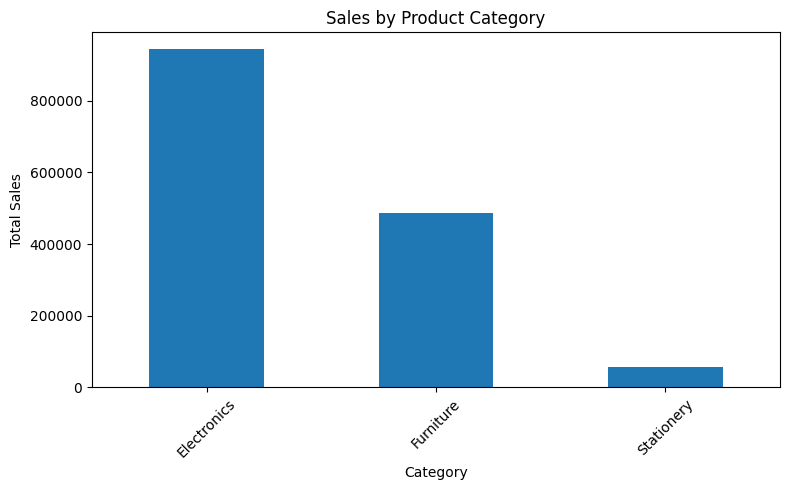

In [7]:
# 9. Bar chart
category_sales.plot(
 kind="bar",
 figsize=(8, 5)
 )
plt.title("Sales by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

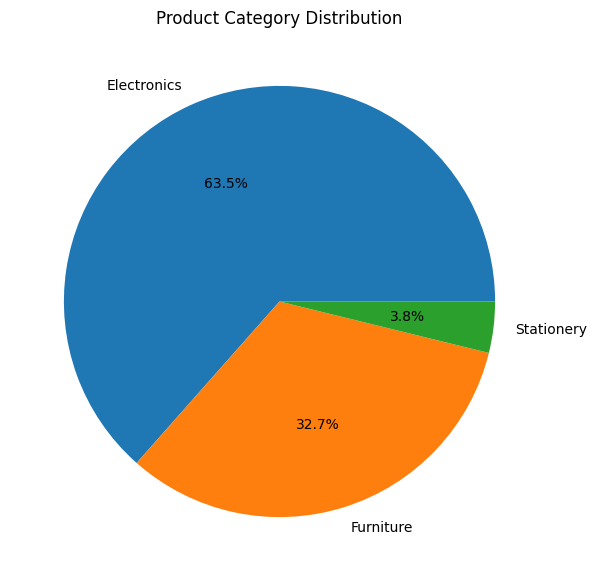

In [8]:
# 10. Pie chart
category_sales.plot(
 kind="pie",
 autopct="%1.1f%%",
 figsize=(7, 7)
 )
plt.title("Product Category Distribution")
plt.ylabel("")
plt.show()